#Import Libraries

In [ ]:

# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torchvision.models as models
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
from torch.utils.data import DataLoader
from google.colab import drive

# Set GPU device

In [1]:
print(torch.cuda.is_available())
device = torch.device("cuda:0")

NameError: name 'torch' is not defined

#Mounting the google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Define class names

In [ ]:
class_names = ['potato late blight', 'potato healthy','potato early blight']

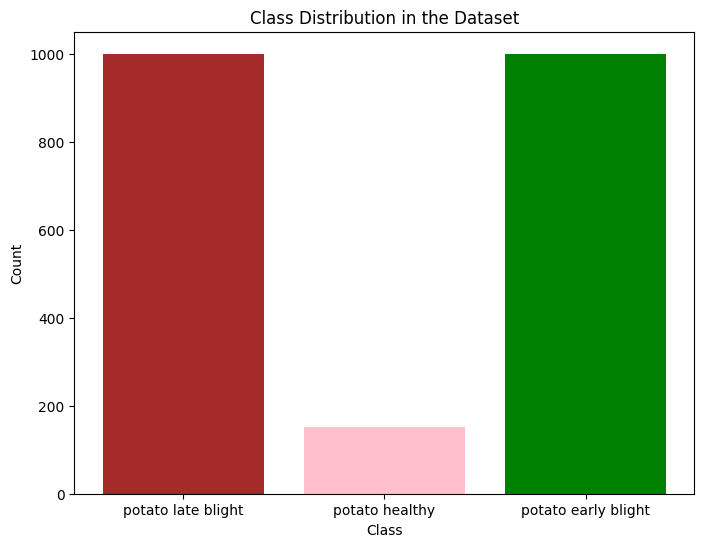

In [ ]:
import matplotlib.pyplot as plt

# Class names and their corresponding counts
class_names = ['potato late blight', 'potato healthy','potato early blight']
class_counts = [1000, 152, 1000]  # Replace with actual counts

# Create a bar chart
plt.figure(figsize=(8, 6))
plt.bar(class_names, class_counts, color=['brown', 'pink',  'green'])

# Add titles and labels
plt.title('Class Distribution in the Dataset')
plt.xlabel('Class')
plt.ylabel('Count')

# Show the chart
plt.show()

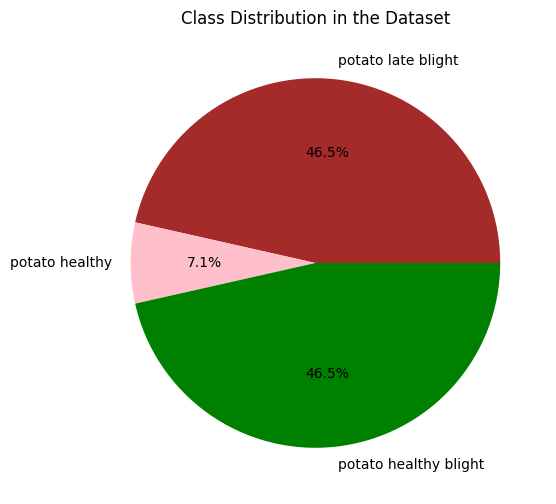

In [ ]:
import matplotlib.pyplot as plt

# Class names and their corresponding counts
class_names = ['potato late blight', 'potato healthy','potato healthy blight']
class_counts = [1000, 152, 1000]  # Replace with actual counts

# Create a pie chart
plt.figure(figsize=(6, 6))
plt.pie(class_counts, labels=class_names, autopct='%1.1f%%', colors=['brown', 'pink', 'green'])

# Add a title
plt.title('Class Distribution in the Dataset')

# Show the chart
plt.show()

# Loading dataset

In [ ]:
TRAIN_ROOT = "/content/drive/MyDrive/potato disease/Train"
TEST_ROOT = "/content/drive/MyDrive/potato disease/Test"

# Define data transformations

In [ ]:
# Define data transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
train_dataset = torchvision.datasets.ImageFolder(root=TRAIN_ROOT, transform=transform)
test_dataset = torchvision.datasets.ImageFolder(root=TEST_ROOT, transform=transform)

In [ ]:
print("Number of images in training dataset:", len(train_dataset))

Number of images in training dataset: 1721


In [ ]:
print("Number of images in testing dataset:", len(test_dataset))

Number of images in testing dataset: 431


In [ ]:
# Function to show images with labels
def imshow_with_labels(imgs, labels, class_names):
    imgs = imgs / 2 + 0.5  # unnormalize
    npimg = imgs.numpy()
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(np.transpose(npimg, (1, 2, 0)))
    ax.axis('off')

    # Annotate each image with its corresponding label
    for i in range(16):
        row = i // 4
        col = i % 4
        ax.text(
            col * 224 + 10,  # x position
            row * 224 + 210, # y position (near the bottom of the image)
            class_names[labels[i]],
            bbox=dict(facecolor='white', alpha=0.7),
            fontsize=12, color='black'
        )
    plt.show()

# Display 4x4 images from a dataset with labels
def show_images_grid_with_labels(dataset, class_names):
    # Create a DataLoader
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=True)
    # Get a batch of images
    images, labels = next(iter(dataloader))

    # Display images with labels
    imshow_with_labels(torchvision.utils.make_grid(images, nrow=4), labels, class_names)

# Show 4x4 images from training data
show_images_grid_with_labels(train_dataset, class_names)

# Show 4x4 images from testing data
show_images_grid_with_labels(test_dataset, class_names)

Output hidden; open in https://colab.research.google.com to view.

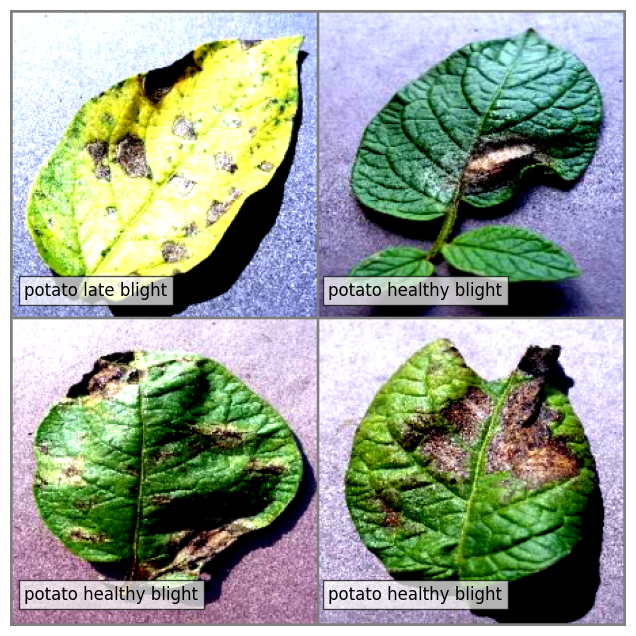

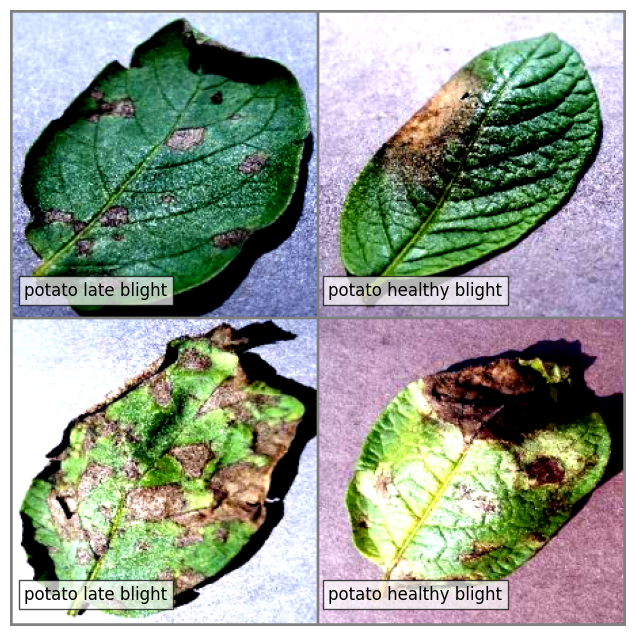

In [ ]:
# Function to show images with labels
def imshow_with_labels(imgs, labels, class_names):
    imgs = imgs / 2 + 0.5  # unnormalize
    npimg = imgs.numpy()
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(np.transpose(npimg, (1, 2, 0)))
    ax.axis('off')

    # Annotate each image with its corresponding label
    for i in range(4):
        row = i // 2
        col = i % 2
        ax.text(
            col * 224 + 10,  # x position
            row * 224 + 210, # y position (near the bottom of the image)
            class_names[labels[i]],
            bbox=dict(facecolor='white', alpha=0.7),
            fontsize=12, color='black'
        )
    plt.show()

# Display 2x2 images from a dataset with labels
def show_images_grid_with_labels(dataset, class_names):
    # Create a DataLoader
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=4, shuffle=True)
    # Get a batch of images
    images, labels = next(iter(dataloader))

    # Display images with labels
    imshow_with_labels(torchvision.utils.make_grid(images, nrow=2), labels, class_names)

# Show 2x2 images from training data
show_images_grid_with_labels(train_dataset, class_names)

# Show 2x2 images from testing data
show_images_grid_with_labels(test_dataset, class_names)


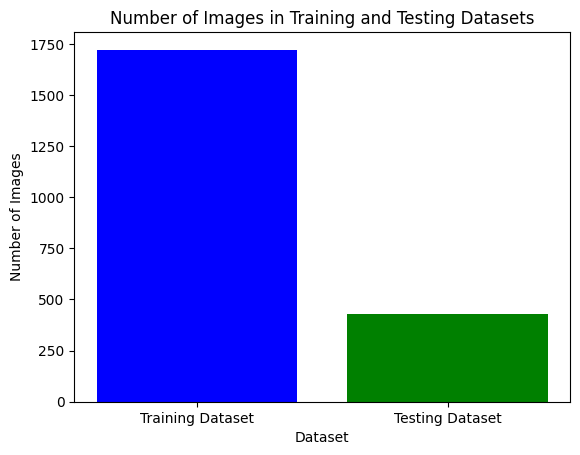

In [ ]:

# Number of images in each dataset
training_images = len(train_dataset)
testing_images = len(test_dataset)

# Labels for the bars
labels = ['Training Dataset', 'Testing Dataset']

# Data to plot
data = [training_images, testing_images]

# Create a bar chart
plt.bar(labels, data, color=['blue', 'green'])

# Add titles and labels
plt.title('Number of Images in Training and Testing Datasets')
plt.xlabel('Dataset')
plt.ylabel('Number of Images')

# Show the chart
plt.show()

#Load Pre-trained ResNet-34 Model

In [ ]:
# Load pre-trained ResNet-34 model
resnet34 = models.resnet34(pretrained=True)

# Modify the final layer to output 4 classes
num_features = resnet34.fc.in_features
resnet34.fc = nn.Linear(num_features, 4)

# Move the model to GPU if available
resnet34 = resnet34.to(device)

RuntimeError: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx

# Define data loaders

In [ ]:

batch_size = 15
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


# Set loss function and optimizer

In [ ]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet34.parameters(), lr=0.0001)
num_epochs = 15  # Number of epochs

Epoch [1/15]
Training Loss: 0.0907, Training Accuracy: 97.50%
Testing Loss: 0.2697, Testing Accuracy: 87.50%
Epoch [2/15]
Training Loss: 0.0299, Training Accuracy: 99.38%
Testing Loss: 0.1339, Testing Accuracy: 95.00%
Epoch [3/15]
Training Loss: 0.0192, Training Accuracy: 99.75%
Testing Loss: 0.1850, Testing Accuracy: 95.00%
Epoch [4/15]
Training Loss: 0.0149, Training Accuracy: 99.75%
Testing Loss: 0.1002, Testing Accuracy: 95.50%
Epoch [5/15]
Training Loss: 0.0277, Training Accuracy: 99.25%
Testing Loss: 0.1014, Testing Accuracy: 97.00%
Epoch [6/15]
Training Loss: 0.0052, Training Accuracy: 99.88%
Testing Loss: 0.0782, Testing Accuracy: 98.50%
Epoch [7/15]
Training Loss: 0.0117, Training Accuracy: 99.62%
Testing Loss: 0.0816, Testing Accuracy: 97.50%
Epoch [8/15]
Training Loss: 0.0127, Training Accuracy: 99.50%
Testing Loss: 0.1389, Testing Accuracy: 97.00%
Epoch [9/15]
Training Loss: 0.0037, Training Accuracy: 99.88%
Testing Loss: 0.1530, Testing Accuracy: 97.00%
Epoch [10/15]
Train

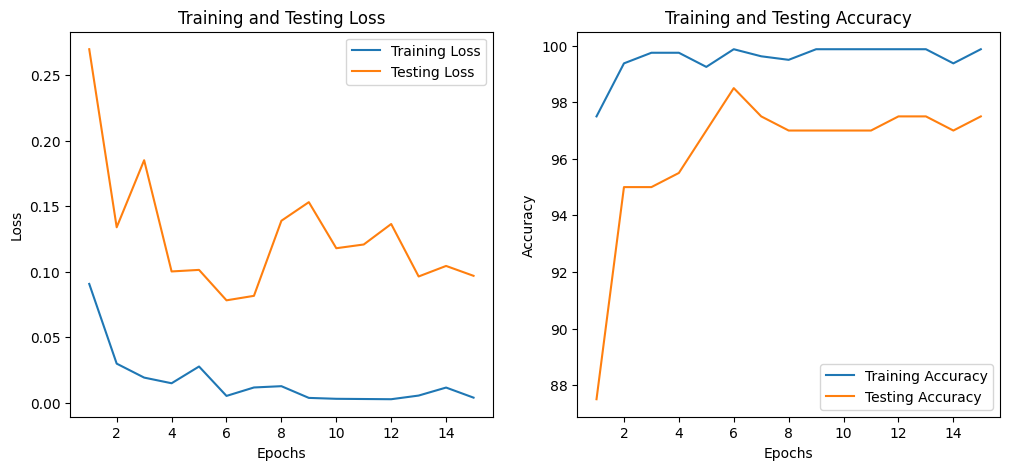

In [ ]:
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# Function to calculate accuracy
def calculate_accuracy(loader, model, device):
    model.eval()  # Set the model to evaluation mode
    correct = 0
    total = 0
    running_loss = 0.0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    average_loss = running_loss / len(loader)
    model.train()  # Set the model back to training mode

    return accuracy, average_loss

for epoch in range(num_epochs):
    resnet34.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet34(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Calculate training accuracy and loss
    train_accuracy, train_loss = calculate_accuracy(train_loader, resnet34, device)

    # Calculate testing accuracy and loss
    test_accuracy, test_loss = calculate_accuracy(test_loader, resnet34, device)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    print(f"Epoch [{epoch + 1}/{num_epochs}]")
    print(f"Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.2f}%")
    print(f"Testing Loss: {test_loss:.4f}, Testing Accuracy: {test_accuracy:.2f}%")

print("Finished Training")
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

# Plot training and testing accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, label='Training Accuracy')
plt.plot(epochs_range, test_accuracies, label='Testing Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracy')
plt.legend()

# Plot training and testing loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Training Loss')
plt.plot(epochs_range, test_losses, label='Testing Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Testing Loss')
plt.legend()

plt.show()

In [ ]:
import random

# Function to display at least one image of each class in a 2x2 grid
def show_at_least_one_per_class_2x2(test_loader, class_names, model, device):
    n_classes = len(class_names)
    model.eval()  # Set model to evaluation mode

    class_images = [None] * n_classes  # Placeholder for one image per class
    additional_images = []  # Extra images to fill the grid

    # Collect images for each class
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predictions = torch.max(outputs, 1)

        for img, label, pred in zip(images, labels, predictions):
            class_idx = label.item()
            if class_images[class_idx] is None:  # Select one image per class
                class_images[class_idx] = (img.cpu(), label.cpu(), pred.cpu())
            else:
                additional_images.append((img.cpu(), label.cpu(), pred.cpu()))

        if all(img is not None for img in class_images):
            break

    # Select up to 4 unique classes and fill the remaining slots randomly
    selected_images = [img for img in class_images if img is not None][:4]
    while len(selected_images) < 4:
        selected_images.append(random.choice(additional_images))

    # Prepare the 4 images, labels, and predictions
    imgs = torch.stack([img for img, _, _ in selected_images])
    labels = [label.item() for _, label, _ in selected_images]
    predictions = [pred.item() for _, _, pred in selected_images]

    # Create a 2x2 grid
    grid_img = torchvision.utils.make_grid(imgs, nrow=2, normalize=True, scale_each=True)

    # Display the grid with annotations
    plt.figure(figsize=(8, 8))
    plt.imshow(np.transpose(grid_img.numpy(), (1, 2, 0)))
    plt.axis('off')

    for i, (label, prediction) in enumerate(zip(labels, predictions)):
        correct = "✔" if label == prediction else "✘"
        color = 'green' if label == prediction else 'red'
        plt.text(
            (i % 2) * (grid_img.size(2) / 2) + 10,  # x position
            (i // 2) * (grid_img.size(1) / 2) + 20, # y position
            f"{class_names[label]} ({correct})",
            bbox=dict(facecolor='white', alpha=0.8),
            fontsize=10, color=color
        )

    plt.suptitle("2x2 Grid: At Least One Image per Class (✔/✘)", fontsize=16)
    plt.show()

# Example usage
show_at_least_one_per_class_2x2(test_loader, class_names, resnet34, device)

NameError: name 'test_loader' is not defined

#Confusion Matrix

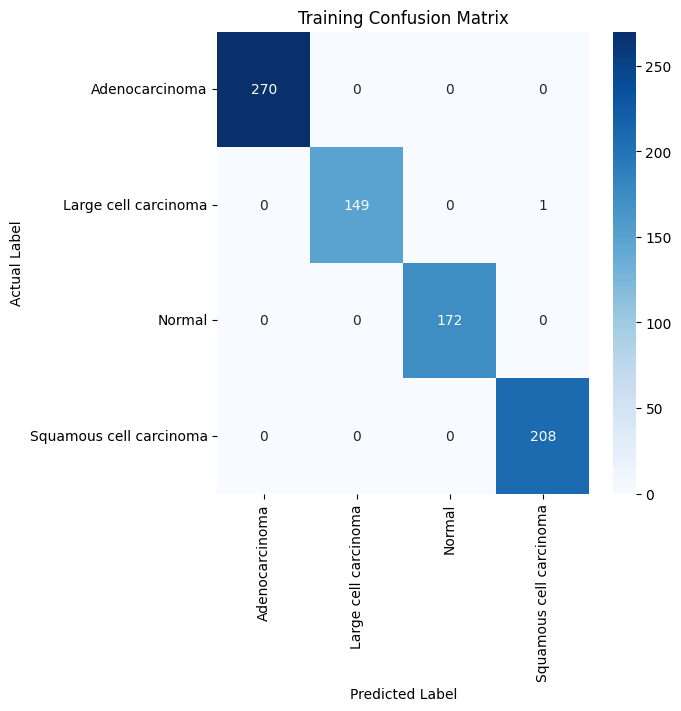

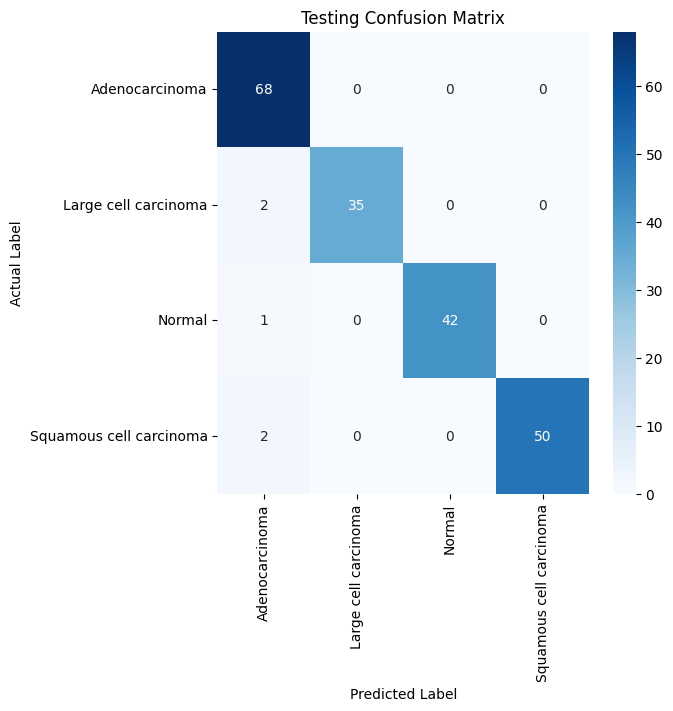

In [ ]:
# Function to calculate confusion matrix
def calculate_confusion_matrix(loader, model, device):
    all_preds = []
    all_labels = []

    model.eval()
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return confusion_matrix(all_labels, all_preds)

# Function to plot confusion matrix
def plot_confusion_matrix(cm, class_names, title='Confusion Matrix'):
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Calculate confusion matrices
train_cm = calculate_confusion_matrix(train_loader, resnet34, device)
test_cm = calculate_confusion_matrix(test_loader, resnet34, device)

# Plot confusion matrices
plot_confusion_matrix(train_cm, class_names, title='Training Confusion Matrix')
plot_confusion_matrix(test_cm, class_names, title='Testing Confusion Matrix')

#Model Saving

In [ ]:

# Function to save the model
def save_model(model, optimizer, path):
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'class_names': class_names,
        'epoch': num_epochs
    }, path)
    print(f"Model saved to {path}")

# Define the path where you want to save the model
save_path = "/content/drive/MyDrive/Colab Notebooks/Lungs Dataset/Lungs_resnet34.pth"

# Save the model
save_model(resnet34, optimizer, save_path)

Model saved to /content/drive/MyDrive/Colab Notebooks/Lungs Dataset/Lungs_resnet34.pth


#Loading Model

In [ ]:
# Function to load the model
def load_model(model, optimizer, path, device):
    checkpoint = torch.load(path)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    class_names = checkpoint['class_names']
    num_epochs = checkpoint['epoch']
    model.to(device)
    model.eval()  # Set the model to evaluation mode
    print(f"Model loaded from {path}")
    return model, optimizer, class_names, num_epochs

# Load the model
load_path = "/content/drive/MyDrive/Colab Notebooks/Lungs Dataset/Lungs_resnet34.pth"
vgg16, optimizer, class_names, num_epochs = load_model(resnet34, optimizer, load_path, device)